# 02 - Ablation (Q3)

Same model, shrinking feature sets from `config.yaml`. Plot the degradation curve.

**Pass (pre-registered `gates.q3`):** the text-free `[cwe, cvss]` set retains >= 50% of the
full model's macro-F1 gain over majority (25-50% = degrades, < 25% = cliff).

In [1]:
import pandas as pd
from src.config import load_config, data_path

pd.set_option("display.width", 140)
cfg = load_config()
interim, processed = data_path(cfg, "interim"), data_path(cfg, "processed")

sector


,feature_set,macro_f1_mean,macro_f1_sd,accuracy_mean
0,text,0.569,0.018,0.726
1,text+cwe,0.509,0.026,0.641
2,text+cwe+cvss,0.503,0.016,0.643
3,cwe+cvss,0.284,0.019,0.402


time_to_kev


,feature_set,macro_f1_mean,macro_f1_sd,accuracy_mean
0,text,0.521,0.074,0.555
1,text+cwe,0.501,0.043,0.533
2,text+cwe+cvss,0.503,0.024,0.538
3,cwe+cvss,0.434,0.028,0.458


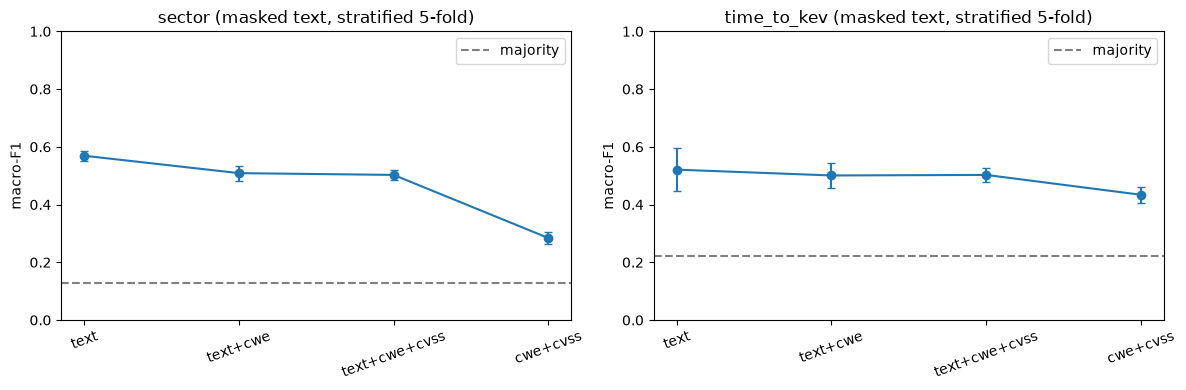

In [2]:
import json
import matplotlib.pyplot as plt

results = {t: json.loads((processed / f"results_{t}.json").read_text()) for t in cfg["targets"]}
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4), squeeze=False)
for ax, (target, r) in zip(axes[0], results.items()):
    abl = pd.DataFrame(r["ablation"])
    ax.errorbar(abl["feature_set"], abl["macro_f1_mean"], yerr=abl["macro_f1_sd"], marker="o", capsize=3)
    ax.axhline(r["signal"]["majority"]["macro_f1_mean"], ls="--", c="grey", label="majority")
    ax.set_title(f"{target} (masked text, stratified 5-fold)")
    ax.set_ylabel("macro-F1"); ax.set_ylim(0, 1); ax.legend(); ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
for target, r in results.items():
    print(target); display(pd.DataFrame(r["ablation"])[["feature_set", "macro_f1_mean", "macro_f1_sd", "accuracy_mean"]].round(3))

## Q3 decision

In [3]:
{t: r['q3'] for t, r in results.items()}

{'sector': {'retention': 0.41491840766760824, 'verdict': 'degrades'},
 'time_to_kev': {'retention': 0.7550341488529311, 'verdict': 'pass'}}